S24CSEU1488

Harshit Batra

Stage 1
Project goal is to create a food delivery prediction, we have to predict food delivery time using the features 

Code -> Data preprocessing, training, evaluation, and visualization code	Results may change and the workflow may no longer be reproducible.

Data ->  data/delivery_times.csv	 Changed data can produce different model results and make experiments impossible to compare fairly.

Model ->	Trained model, parameters, and evaluation metrics	Predictions may change and the deployed model may no longer match the evaluated model.

Python environment/library requirements:
Python 3.14.1
pandas
numpy
scikit-learn
matplotlib


Project workflow:
Data → Features → Train → Evaluate → Compare → Search → Visualize

In [3]:
!pip install pandas numpy matplotlib seaborn scikit-learn tpot


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [5]:
df = pd.read_csv("delivery_times.csv")

print("Dataset:")
print(df.head())
print("\nShape:", df.shape)
print("\nColumns:")
print(df.columns)

Dataset:
   distance_km  prep_time_min  traffic_level  rain  delivery_min
0         9.40             17              1     0          51.3
1         5.55             24              2     1          54.2
2        10.37             28              3     0          67.7
3         8.52             23              2     0          51.2
4         1.58             29              2     1          42.1

Shape: (600, 5)

Columns:
Index(['distance_km', 'prep_time_min', 'traffic_level', 'rain',
       'delivery_min'],
      dtype='str')


In [6]:
df.isnull().sum()

distance_km      0
prep_time_min    0
traffic_level    0
rain             0
delivery_min     0
dtype: int64

In [7]:
df.shape

(600, 5)

In [8]:
X = df.drop("delivery_min", axis=1)
y = df["delivery_min"]

categorical_features = ["traffic_level"]
numerical_features = [
    "distance_km",
    "prep_time_min",
    "rain"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=999
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 480
Testing samples: 120


In [10]:
baseline_prediction = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_prediction
    )
)

print("\nBaseline")
print("MAE :", baseline_mae)
print("RMSE:", baseline_rmse)



Baseline
MAE : 9.774864583333335
RMSE: 11.693793390634504


In [11]:
models = {
    "Linear Regression": LinearRegression(),

    "SVR": SVR(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),

    "kNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    )
}

In [12]:
results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

    trained_models[name] = pipeline

    print(f"\n{name}")
    print(f"MAE : {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")




Linear Regression
MAE : 1.8960
RMSE: 2.4297

SVR
MAE : 2.3874
RMSE: 3.1172

Random Forest
MAE : 2.2173
RMSE: 2.8266

kNN
MAE : 2.2573
RMSE: 2.8418

Decision Tree
MAE : 3.2958
RMSE: 4.1181


In [13]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE"
)

print(results_df.to_string(index=False))

best_model = results_df.iloc[0]

print("\nBest model:", best_model["Model"])
print("Best MAE:", best_model["MAE"])
print("Best RMSE:", best_model["RMSE"])


            Model      MAE     RMSE
Linear Regression 1.896017 2.429682
    Random Forest 2.217321 2.826616
              kNN 2.257333 2.841820
              SVR 2.387411 3.117168
    Decision Tree 3.295833 4.118060

Best model: Linear Regression
Best MAE: 1.8960170877819418
Best RMSE: 2.4296824056183235


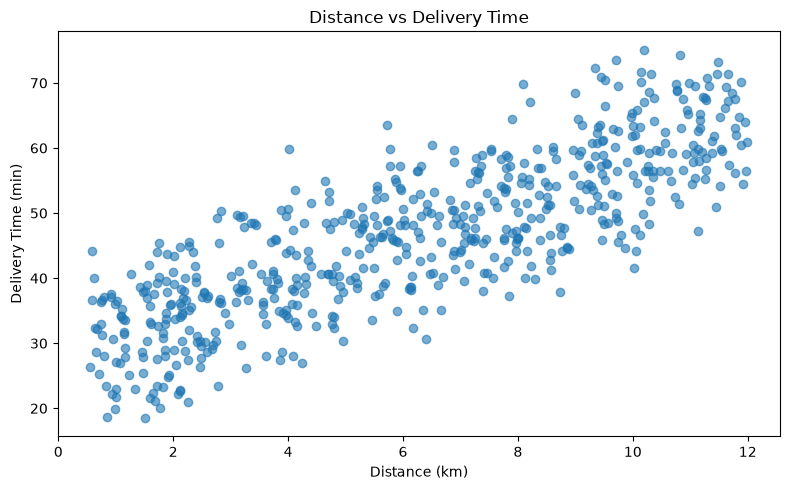

In [14]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["distance_km"],
    df["delivery_min"],
    alpha=0.6
)

plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (min)")
plt.title("Distance vs Delivery Time")

plt.tight_layout()
plt.show()


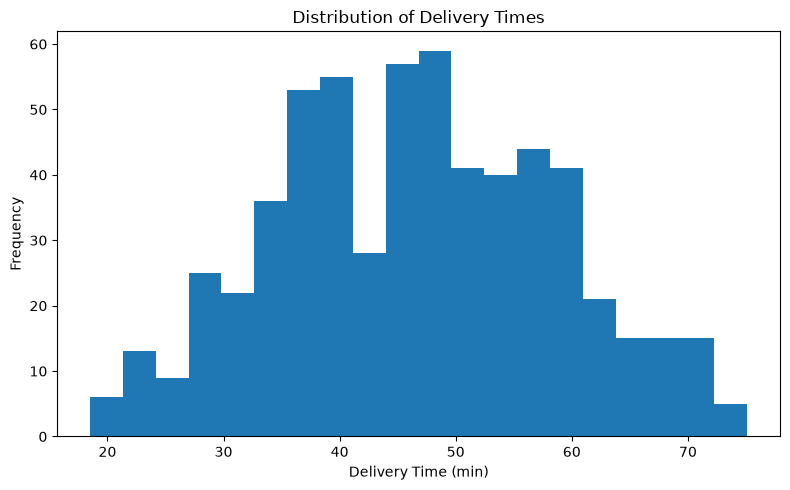

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["delivery_min"],
    bins=20
)

plt.xlabel("Delivery Time (min)")
plt.ylabel("Frequency")
plt.title("Distribution of Delivery Times")

plt.tight_layout()
plt.show()

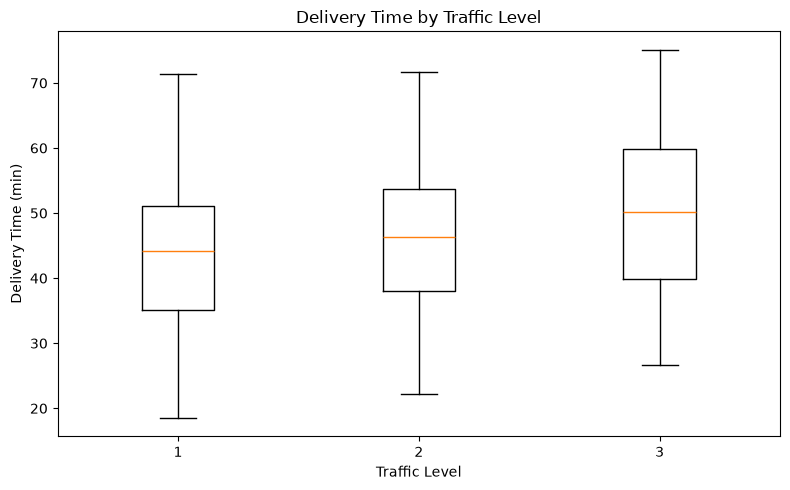

In [16]:
traffic_groups = [
    df[df["traffic_level"] == level]["delivery_min"]
    for level in sorted(df["traffic_level"].unique())
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    traffic_groups
)

plt.xlabel("Traffic Level")
plt.ylabel("Delivery Time (min)")
plt.title("Delivery Time by Traffic Level")

plt.tight_layout()
plt.show()

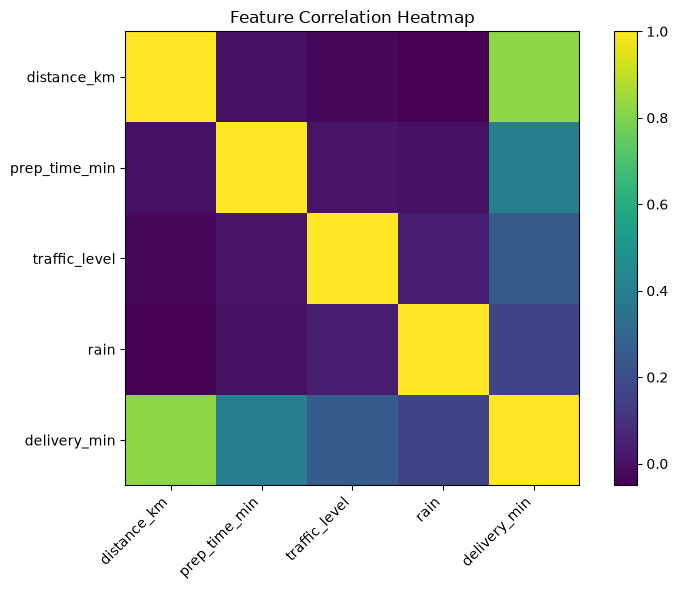

In [17]:
numeric_df = df.copy()

numeric_df["traffic_level"] = pd.to_numeric(
    numeric_df["traffic_level"]
)

correlation = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation,
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()



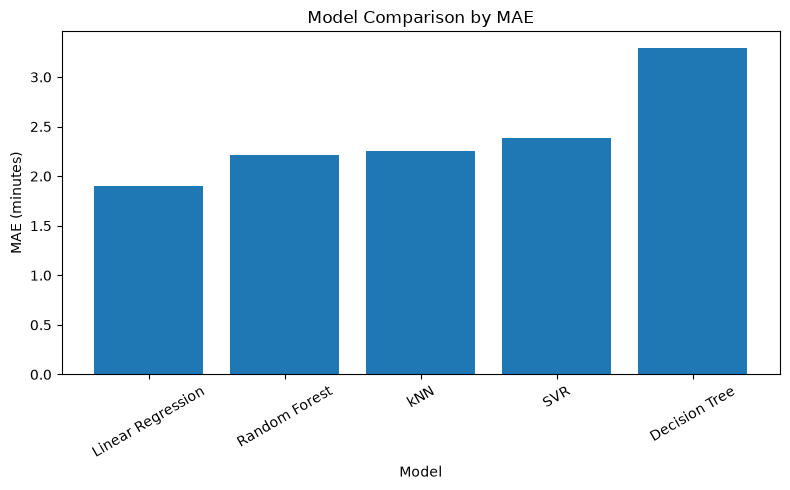

In [18]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["MAE"]
)

plt.xlabel("Model")
plt.ylabel("MAE (minutes)")
plt.title("Model Comparison by MAE")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [19]:
!pip install tpot


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [27]:
from tpot import TPOTRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

print("\n================ TPOT AUTOML ================")

X_encoded = pd.get_dummies(
    X,
    columns=["traffic_level"],
    drop_first=False
)

X_train_auto, X_test_auto, y_train_auto, y_test_auto = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

tpot = TPOTRegressor(
    generations=5,
    population_size=10,
    random_state=42,
    n_jobs=1,
    verbose=2
)

tpot.fit(
    X_train_auto,
    y_train_auto
)

predictions = tpot.predict(X_test_auto)

mae = mean_absolute_error(
    y_test_auto,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_auto,
        predictions
    )
)

print("\n================ TPOT RESULT ================")
print("Best Pipeline:")
print(tpot.fitted_pipeline_)

print(f"\nTest MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")


================ TPOT AUTOML ================


/home/nick/.pyenv/versions/3.11.9/lib/python3.11/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 34671 instead
  warnings.warn(
Generation: 100%|██████████| 5/5 [04:40<00:00, 56.10s/it]
/home/nick/.pyenv/versions/3.11.9/lib/python3.11/site-packages/sklearn/ensemble/_forest.py:2694: FutureWarning: Value `"friedman_mse"` for `criterion` is deprecated and will be removed in 1.11. It maps to `"squared_error"` as both were always equivalent. Use `criterion="squared_error"` to remove this warning.
  warn(



================ TPOT RESULT ================
Best Pipeline:
Pipeline(steps=[('robustscaler',
                 RobustScaler(quantile_range=(0.1373094877432,
                                              0.9679539298163))),
                ('selectfrommodel',
                 SelectFromModel(estimator=ExtraTreesRegressor(bootstrap=np.True_,
                                                               criterion=np.str_('squared_error'),
                                                               max_features=0.6461855611182,
                                                               min_samples_leaf=8,
                                                               min_samples_split=16,
                                                               n_jobs=1,
                                                               random_state=42),
                                 threshold=0.0084536361245)),
                ('featureuni...
                 FeatureUnion(transformer_list=[(

In [ ]:
print("\n================ FINAL SUMMARY ================")

print("Baseline MAE:", round(baseline_mae, 4))

print("\nManual Models:")
print(results_df.to_string(index=False))

print("\nBest Manual Model:")
print(best_model["Model"])

print(
    "\nThe test set was kept separate from training "
    "to provide an unbiased evaluation."
)


================ FINAL SUMMARY ================
Baseline MAE: 9.7749

Manual Models:
            Model      MAE     RMSE
Linear Regression 1.896017 2.429682
    Random Forest 2.217321 2.826616
              kNN 2.257333 2.841820
              SVR 2.387411 3.117168
    Decision Tree 3.295833 4.118060

Best Manual Model:
Linear Regression

The test set was kept separate from training to provide an unbiased evaluation.
